# 04 · Training BPR-MF and SASRec

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Souhaila-DJAFFAL/longtail-recsys/blob/main/notebooks/04_training.ipynb)

Trains both learned models on the training interactions, using **validation NDCG@10 for early stopping**
(the test targets are never seen during training or model selection), then saves the best checkpoints.


In [7]:
# --- Setup: works locally (Jupyter) and on Google Colab ---
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("02_models.ipynb"):
    !git clone -q https://github.com/Souhaila-DJAFFAL/longtail-recsys.git
    %cd longtail-recsys/notebooks
    !pip install -q tabulate

DATASET = os.environ.get("RECSYS_DATASET", "ml-1m")  # "ml-1m" (real) or "synthetic" (fast check)
QUICK = os.environ.get("RECSYS_QUICK", "0") == "1"     # few epochs, for smoke tests only
ARTIFACTS, RESULTS = "../artifacts", "../results"
os.makedirs(ARTIFACTS, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

In [8]:
%run 02_models.ipynb
%run 03_evaluation_metrics.ipynb

Popularity score shape (4, 31)  params 0
BPRMF      score shape (4, 31)  params 608
SASRec     score shape (4, 31)  params 4,112
All evaluation self-tests passed.


In [10]:
import copy, json, time
import matplotlib.pyplot as plt
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
data = load_dataset()
MAX_LEN = 200 if DATASET == "ml-1m" else 50

CONFIG = {
    "dataset": DATASET, "seed": SEED, "k": 10, "max_len": MAX_LEN,
    "bpr":    {"dim": 64, "lr": 5e-3, "weight_decay": 1e-6, "batch_size": 4096,
               "epochs": 4 if QUICK else 200, "eval_every": 2 if QUICK else 5, "patience": 5},
    "sasrec": {"dim": 64, "n_blocks": 2, "n_heads": 1, "dropout": 0.2, "lr": 1e-3, "batch_size": 128,
               "epochs": 4 if QUICK else 400, "eval_every": 2 if QUICK else 10, "patience": 5},
}
print(f"device={DEVICE}  users={data.n_users:,}  items={data.n_items:,}")

device=cuda  users=6,040  items=3,416


## Shared pieces: negative sampling and early stopping

* **Negative sampling.** For each positive interaction, one item the user has *not* interacted with is
  drawn uniformly at random.
* **Early stopping.** Every few epochs the model is evaluated on the validation targets; training stops
  after `patience` evaluations without improvement and the best weights are restored.

In [11]:
def sample_negatives(rng, n_items, shape, user_sets):
    """Uniform negatives in 1..n_items, resampled while the user has already seen the item."""
    neg = rng.integers(1, n_items + 1, size=shape)
    for r, seen in enumerate(user_sets):
        row = neg[r] if neg.ndim > 1 else neg[r:r + 1]
        for c in range(row.shape[0]):
            while row[c] in seen:
                row[c] = rng.integers(1, n_items + 1)
    return neg


def fit(model, step_fn, cfg, name):
    """Run training epochs with periodic validation and early stopping."""
    best, best_state, bad, history = -1.0, None, 0, []
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        model.train()
        loss = step_fn()
        if epoch % cfg["eval_every"] == 0 or epoch == cfg["epochs"]:
            ndcg = evaluate(model, data, "valid", k=CONFIG["k"], max_len=MAX_LEN, device=DEVICE)[0]["NDCG@10"]
            history.append({"epoch": epoch, "loss": loss, "valid_ndcg": float(ndcg)})
            print(f"[{name}] epoch {epoch:4d}  loss {loss:.4f}  valid NDCG@10 {ndcg:.4f}  ({time.time() - t0:.1f}s/epoch)")
            if ndcg > best:
                best, best_state, bad = ndcg, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if bad >= cfg["patience"]:
                    print(f"[{name}] early stopping; best valid NDCG@10 = {best:.4f}")
                    break
    model.load_state_dict(best_state)
    return model, history

## BPR-MF

Each epoch shuffles all training interactions $(u, i)$, pairs each with a sampled negative $j$, and
minimizes $-\log\sigma(\hat{x}_{ui} - \hat{x}_{uj})$ with Adam.

In [12]:
def train_bpr(cfg):
    torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
    model = BPRMF(data.n_users, data.n_items, cfg["dim"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    users = np.concatenate([[u] * len(s) for u, s in enumerate(data.train)])
    items = np.concatenate(data.train)
    user_sets = [set(s) for s in data.train]

    def step():
        perm, total = rng.permutation(len(users)), 0.0
        for b in range(0, len(perm), cfg["batch_size"]):
            idx = perm[b:b + cfg["batch_size"]]
            neg = sample_negatives(rng, data.n_items, len(idx), [user_sets[x] for x in users[idx]])
            u, i, j = (torch.as_tensor(a, device=DEVICE) for a in (users[idx], items[idx], neg))
            pos_s, neg_s = model(u, i, j)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        return total / len(perm)

    return fit(model, step, cfg, "BPR-MF")


t0 = time.time()
bpr, bpr_hist = train_bpr(CONFIG["bpr"])
CONFIG["bpr"]["train_minutes"] = round((time.time() - t0) / 60, 1)

[BPR-MF] epoch    5  loss 0.1796  valid NDCG@10 0.0342  (3.1s/epoch)
[BPR-MF] epoch   10  loss 0.1412  valid NDCG@10 0.0346  (3.0s/epoch)
[BPR-MF] epoch   15  loss 0.1254  valid NDCG@10 0.0387  (3.6s/epoch)
[BPR-MF] epoch   20  loss 0.1185  valid NDCG@10 0.0385  (2.5s/epoch)
[BPR-MF] epoch   25  loss 0.1149  valid NDCG@10 0.0381  (2.5s/epoch)
[BPR-MF] epoch   30  loss 0.1120  valid NDCG@10 0.0391  (2.5s/epoch)
[BPR-MF] epoch   35  loss 0.1107  valid NDCG@10 0.0382  (2.6s/epoch)
[BPR-MF] epoch   40  loss 0.1099  valid NDCG@10 0.0386  (2.7s/epoch)
[BPR-MF] epoch   45  loss 0.1088  valid NDCG@10 0.0385  (3.6s/epoch)
[BPR-MF] epoch   50  loss 0.1079  valid NDCG@10 0.0397  (2.8s/epoch)
[BPR-MF] epoch   55  loss 0.1079  valid NDCG@10 0.0382  (2.5s/epoch)
[BPR-MF] epoch   60  loss 0.1072  valid NDCG@10 0.0401  (2.5s/epoch)
[BPR-MF] epoch   65  loss 0.1070  valid NDCG@10 0.0390  (2.6s/epoch)
[BPR-MF] epoch   70  loss 0.1070  valid NDCG@10 0.0399  (2.5s/epoch)
[BPR-MF] epoch   75  loss 0.1071  

## SASRec

For every user, the input is the training sequence without its last item and the targets are the same
sequence shifted by one, so each position learns to predict the next item. The loss is binary
cross-entropy on the positive next item and one sampled negative, averaged over non-padding positions.

In [13]:
def train_sasrec(cfg):
    torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
    model = SASRec(data.n_items, MAX_LEN, cfg["dim"], cfg["n_blocks"], cfg["n_heads"], cfg["dropout"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], betas=(0.9, 0.98))
    inputs = pad_left([s[:-1] for s in data.train], MAX_LEN)
    targets = pad_left([s[1:] for s in data.train], MAX_LEN)
    user_sets = [set(s) for s in data.train]

    def step():
        perm, total, count = rng.permutation(data.n_users), 0.0, 0
        for b in range(0, len(perm), cfg["batch_size"]):
            idx = perm[b:b + cfg["batch_size"]]
            neg = sample_negatives(rng, data.n_items, targets[idx].shape, [user_sets[u] for u in idx])
            seq, pos, neg = (torch.as_tensor(a, device=DEVICE) for a in (inputs[idx], targets[idx], neg))
            p, n = model(seq, pos, neg)
            mask = pos != 0
            loss = (F.binary_cross_entropy_with_logits(p, torch.ones_like(p), reduction="none")
                    + F.binary_cross_entropy_with_logits(n, torch.zeros_like(n), reduction="none"))
            loss = (loss * mask).sum() / mask.sum()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * mask.sum().item(); count += mask.sum().item()
        return total / count

    return fit(model, step, cfg, "SASRec")


t0 = time.time()
sasrec, sasrec_hist = train_sasrec(CONFIG["sasrec"])
CONFIG["sasrec"]["train_minutes"] = round((time.time() - t0) / 60, 1)

[SASRec] epoch   10  loss 0.6583  valid NDCG@10 0.0712  (2.3s/epoch)
[SASRec] epoch   20  loss 0.5499  valid NDCG@10 0.0996  (2.7s/epoch)
[SASRec] epoch   30  loss 0.5098  valid NDCG@10 0.1155  (2.5s/epoch)
[SASRec] epoch   40  loss 0.4862  valid NDCG@10 0.1228  (2.4s/epoch)
[SASRec] epoch   50  loss 0.4724  valid NDCG@10 0.1254  (2.4s/epoch)
[SASRec] epoch   60  loss 0.4603  valid NDCG@10 0.1277  (2.7s/epoch)
[SASRec] epoch   70  loss 0.4512  valid NDCG@10 0.1290  (2.5s/epoch)
[SASRec] epoch   80  loss 0.4441  valid NDCG@10 0.1301  (2.4s/epoch)
[SASRec] epoch   90  loss 0.4406  valid NDCG@10 0.1324  (2.4s/epoch)
[SASRec] epoch  100  loss 0.4370  valid NDCG@10 0.1340  (2.5s/epoch)
[SASRec] epoch  110  loss 0.4312  valid NDCG@10 0.1350  (2.7s/epoch)
[SASRec] epoch  120  loss 0.4297  valid NDCG@10 0.1346  (2.3s/epoch)
[SASRec] epoch  130  loss 0.4277  valid NDCG@10 0.1349  (2.3s/epoch)
[SASRec] epoch  140  loss 0.4234  valid NDCG@10 0.1383  (2.3s/epoch)
[SASRec] epoch  150  loss 0.4226  

## Learning curves

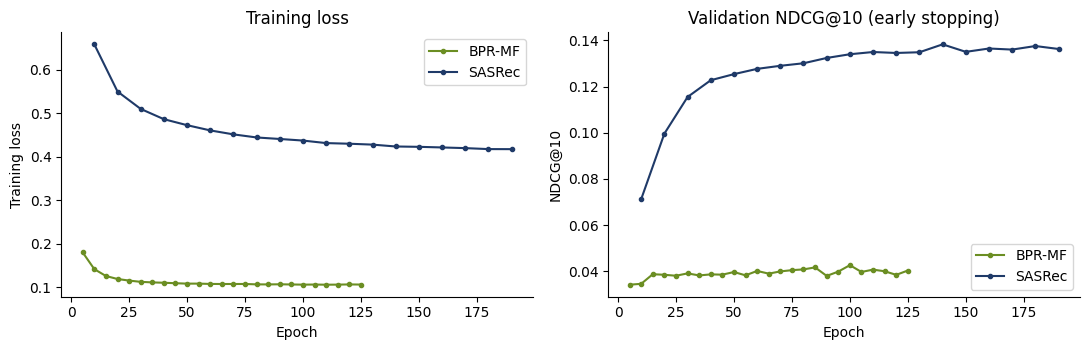

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
colors = {"BPR-MF": "#6b8e23", "SASRec": "#1f3a68"}
for name, hist in [("BPR-MF", bpr_hist), ("SASRec", sasrec_hist)]:
    ep = [h["epoch"] for h in hist]
    axes[0].plot(ep, [h["loss"] for h in hist], marker=".", color=colors[name], label=name)
    axes[1].plot(ep, [h["valid_ndcg"] for h in hist], marker=".", color=colors[name], label=name)
axes[0].set(xlabel="Epoch", ylabel="Training loss", title="Training loss")
axes[1].set(xlabel="Epoch", ylabel="NDCG@10", title="Validation NDCG@10 (early stopping)")
for ax in axes:
    ax.legend(); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(f"{RESULTS}/learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Save checkpoints

In [15]:
torch.save(bpr.state_dict(), f"{ARTIFACTS}/bpr_{DATASET}.pt")
torch.save(sasrec.state_dict(), f"{ARTIFACTS}/sasrec_{DATASET}.pt")
CONFIG.update({"device": DEVICE, "torch": torch.__version__,
               "history": {"bpr": bpr_hist, "sasrec": sasrec_hist}})
with open(f"{ARTIFACTS}/config_{DATASET}.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
print("Saved checkpoints and config to", ARTIFACTS)

Saved checkpoints and config to ../artifacts


**Next:** [`05_results_and_longtail_analysis.ipynb`](05_results_and_longtail_analysis.ipynb) evaluates the models on the test set.